In [1]:
import subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "notebooks" / "output"
OUT.mkdir(parents=True, exist_ok=True)

N_STATIONS, N_DAYS = 4, 238                 # 4 trạm × 238 ngày kiểm thử (01/11/2017 → 26/06/2018)
WINDOW = pd.Timedelta(hours=1)              # cửa sổ khớp: t_end + 1 giờ

# Tạo lại alerts_A/B.csv nếu chưa có (detector không đọc đáp án)
for m in "AB":
    if not (ROOT / f"alerts_{m}.csv").exists():
        subprocess.run([sys.executable, "detector/detector.py", "--source", "csv", "--method", m],
                       cwd=ROOT, check=True)

ev = pd.read_csv(ROOT / "data/event_label.csv", parse_dates=["t_start", "t_breach", "t_end"])
alerts = {m: pd.read_csv(ROOT / f"alerts_{m}.csv",
                         parse_dates=["opened_ts", "escalated_ts", "last_ts", "resolved_ts"])
          for m in "AB"}
print(ev.groupby(["type", "source_type"]).size(), {m: len(a) for m, a in alerts.items()})

Processed 91328 readings; 105 alerts -> alerts_A.csv
Processed 91328 readings; 403 alerts -> alerts_B.csv
type      source_type
OVERLOAD  REAL            9
          SIMULATED       9
SENSOR    REAL           20
dtype: int64 {'A': 105, 'B': 403}


In [2]:
def match(al, ev, rule="goc"):
    """Cặp (cảnh báo, sự cố) khớp: cùng trạm, cùng loại, và
       goc       : opened_ts ∈ [t_start, t_end + 1h]                 (theo đặc tả)
       chong_lan : cảnh báo ĐANG MỞ tại một thời điểm trong [t_start, t_end + 1h]"""
    p = al.reset_index(names="alert_idx").merge(
        ev, left_on=["station_id", "alert_type"], right_on=["station_id", "type"])
    if rule == "goc":
        ok = p.opened_ts.between(p.t_start, p.t_end + WINDOW)
    else:
        ok = (p.opened_ts <= p.t_end + WINDOW) & (p.resolved_ts.isna() | (p.resolved_ts >= p.t_start))
    return p[ok]


def evaluate(al, ev, rule="goc"):
    m = match(al, ev, rule)
    first = m.groupby("event_id").agg(first_open=("opened_ts", "min"), first_red=("escalated_ts", "min"))
    r = ev.set_index("event_id").join(first)            # nhiều cảnh báo / 1 sự cố → tính 1 lần
    r["caught"] = r.first_open.notna()
    r["delay_min"] = (r.first_open - r.t_start).dt.total_seconds() / 60
    r["lead_min"] = (r.t_breach - r.first_red).dt.total_seconds() / 60
    ov, se = r[r.type == "OVERLOAD"], r[r.type == "SENSOR"]
    fp = len(al) - m.alert_idx.nunique()                # cảnh báo không khớp sự cố nào
    metrics = {
        "Recall tổng (%)":        100 * r.caught.mean(),
        "Recall OVERLOAD (%)":    100 * ov.caught.mean(),
        "Recall SENSOR (%)":      100 * se.caught.mean(),
        "Số cảnh báo":            len(al),
        "Báo nhầm (cảnh báo)":    fp,
        "Báo nhầm/trạm/ngày":     fp / (N_STATIONS * N_DAYS),
        "Độ trễ OVERLOAD (phút)": ov.delay_min.mean(),
        "Độ trễ SENSOR (phút)":   se.delay_min.mean(),
        "Lead time (phút)":       ov.lead_min.mean(),
        "Sự cố có lên Đỏ":        ov.lead_min.notna().sum(),
    }
    return r, metrics

In [3]:
RULES = {"goc": "Luật gốc", "chong_lan": "Luật chồng lấn"}
detail, rows = {}, {}
for rule, rule_name in RULES.items():
    for meth, al in alerts.items():
        detail[(rule, meth)], rows[(rule_name, meth)] = evaluate(al, ev, rule)

table = pd.DataFrame(rows).round(2)
table.to_csv(OUT / "eval_summary.csv", encoding="utf-8-sig")
table

Luật gốc         Luật chồng lấn        
                              A       B              A       B
Recall tổng (%)           47.37   86.84          47.37  100.00
Recall OVERLOAD (%)      100.00   72.22         100.00  100.00
Recall SENSOR (%)          0.00  100.00           0.00  100.00
Số cảnh báo              105.00  403.00         105.00  403.00
Báo nhầm (cảnh báo)       81.00  362.00          81.00  355.00
Báo nhầm/trạm/ngày         0.09    0.38           0.09    0.37
Độ trễ OVERLOAD (phút)    31.67  252.69          31.67   19.17
Độ trễ SENSOR (phút)        NaN   45.00            NaN   45.00
Lead time (phút)           0.00 -193.85           0.00   37.50
Sự cố có lên Đỏ           18.00   13.00          18.00   18.00

In [4]:
cols = ["station_id", "detail", "t_start", "t_breach", "first_open", "first_red", "delay_min", "lead_min"]
detail[("goc", "B")].query("type == 'OVERLOAD'")[cols]      # đổi thành ("chong_lan", "B"), ("goc", "A")... để xem

,station_id,detail,t_start,t_breach,first_open,first_red,delay_min,lead_min
event_id,,,,,,,,
EV002,TRAM_2,INJECTED_RAMP,2018-01-04 18:45:00,2018-01-04 20:45:00,2018-01-04 20:15:00,2018-01-04 20:30:00,90.0,15.0
EV003,TRAM_2,INJECTED_RAMP,2018-01-26 18:00:00,2018-01-26 20:45:00,2018-01-26 18:45:00,2018-01-26 20:30:00,45.0,15.0
EV005,TRAM_2,INJECTED_RAMP,2018-02-02 18:45:00,2018-02-02 20:15:00,2018-02-02 19:45:00,2018-02-02 19:45:00,60.0,30.0
EV016,TRAM_4,INJECTED_RAMP,2018-01-17 19:00:00,2018-01-17 20:30:00,2018-01-17 20:00:00,2018-01-17 20:00:00,60.0,30.0
EV017,TRAM_4,INJECTED_RAMP,2018-01-25 17:00:00,2018-01-25 18:00:00,2018-01-25 17:15:00,2018-01-25 17:45:00,15.0,15.0
EV018,TRAM_4,INJECTED_RAMP,2018-02-12 17:30:00,2018-02-12 19:30:00,2018-02-12 18:30:00,2018-02-12 19:15:00,60.0,15.0
EV022,TRAM_Y,REAL_PEAK,2017-12-01 23:00:00,2017-12-02 00:15:00,NaT,NaT,NaN,NaN
EV023,TRAM_Y,REAL_PEAK,2017-12-12 07:00:00,2017-12-12 07:00:00,2017-12-12 07:00:00,2017-12-12 07:00:00,0.0,0.0
EV025,TRAM_Y,INJECTED_RAMP,2018-01-11 18:30:00,2018-01-11 20:45:00,2018-01-11 19:45:00,2018-01-11 19:45:00,75.0,60.0


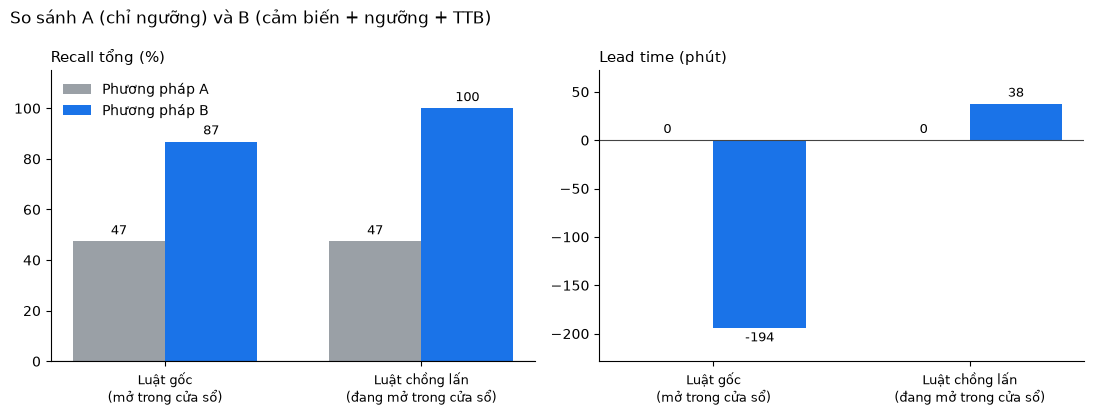

In [5]:
colors = {"A": "#9AA0A6", "B": "#1A73E8"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x, w = np.arange(len(RULES)), 0.36
for ax, metric in zip(axes, ["Recall tổng (%)", "Lead time (phút)"]):
    for i, meth in enumerate("AB"):
        vals = [table.loc[metric, (name, meth)] for name in RULES.values()]
        bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f"Phương pháp {meth}", color=colors[meth])
        ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    ax.set_xticks(x, ["Luật gốc\n(mở trong cửa sổ)", "Luật chồng lấn\n(đang mở trong cửa sổ)"], fontsize=9)
    ax.set_title(metric, loc="left", fontsize=11)
    ax.axhline(0, color="#444", lw=0.8)
    ax.margins(y=0.15)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("So sánh A (chỉ ngưỡng) và B (cảm biến + ngưỡng + TTB)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "eval_chart.png", dpi=150)
plt.show()

In [6]:
b = alerts["B"]
fp_b = b.drop(match(b, ev, "chong_lan").alert_idx.unique())
dur = (fp_b.resolved_ts - fp_b.opened_ts).dt.total_seconds() / 60
r_b, r_a = detail[("chong_lan", "B")], detail[("chong_lan", "A")]
print("Báo nhầm B theo trạm:", fp_b.station_id.value_counts().to_dict())
print("Báo nhầm B theo luật:", fp_b.trigger_rule.value_counts().to_dict())
print(f"Báo nhầm B kéo dài ≤ 30 phút: {(dur <= 30).mean():.0%}")
print("Sự cố bơm – độ trễ TB A/B (phút):",
      r_a.query("detail == 'INJECTED_RAMP'").delay_min.mean().round(1),
      r_b.query("detail == 'INJECTED_RAMP'").delay_min.mean().round(1),
      "| lead time TB B:", r_b.query("detail == 'INJECTED_RAMP'").lead_min.mean().round(1))
print("B lên Đỏ trước t_breach:", (r_b.lead_min > 0).sum(), "/", r_b.lead_min.notna().sum())

Báo nhầm B theo trạm: {'TRAM_Y': 320, 'TRAM_3': 25, 'TRAM_2': 5, 'TRAM_4': 5}
Báo nhầm B theo luật: {'TTB': 326, 'THRESHOLD': 27, 'STUCK': 2}
Báo nhầm B kéo dài ≤ 30 phút: 72%
Sự cố bơm – độ trễ TB A/B (phút): 63.3 56.7 | lead time TB B: 23.3
B lên Đỏ trước t_breach: 14 / 18


## Nhận xét
1. **B bắt đủ sự cố:** recall 100% (38/38), A chỉ 47% vì không bắt được lỗi cảm biến nào (0/20). B phát hiện SENSOR trễ 45 phút do cần 4 bản ghi đứng yên.
2. **B báo Đỏ sớm hơn:** lead time trung bình 38 phút (14/18 sự cố lên Đỏ trước khi vượt 100%), A là 0 phút. Với sự cố bơm, lead time chỉ còn 23 phút, dưới mục tiêu 30 phút.
3. **Điểm yếu của B – báo nhầm gấp 4 lần A:** 0,37 so với 0,09 cảnh báo/trạm/ngày. 326/355 báo nhầm đến từ luật TTB, 320 ở Trạm Y, 72% chỉ kéo dài ≤ 30 phút: TTB nhạy với dao động ngắn, mở khi tải còn thấp rồi đóng ngay.
4. **Điểm yếu của B – phát hiện sự cố bơm chưa sớm hơn nhiều:** độ trễ trung bình 57 phút, so với 63 phút của A, vì TTB cần 1 giờ lịch sử và tải phải tăng nhanh mới kích hoạt.
5. **Hạn chế của đánh giá:** luật khớp gốc tính oan 5 sự cố B đã báo trước `t_start`. Nhãn REAL_PEAK dựng theo luật ngưỡng nên thiên vị A. EV029/EV030 có `t_end` kéo sang ngày sau.